# 高温でのダスト冷却・加熱の見直し

EQCLib のダスト再結合冷却 $L_{\rm DustRec}$ とダスト光電加熱 $H_{\rm PE}$ に温度依存の重みを適用し、変更前後と CHIMES full を比較します。重みは $T\le10^4\,{\rm K}$ で 1、$T\ge10^5\,{\rm K}$ で 0 です。中間では $s=\log_{10}(10^5\,{\rm K}/T)$ として $s^2(3-2s)$ を使います。遷移の下端は Bakes & Tielens の光電加熱フィットの適用上限に合わせ、上端はこの比較で使う CHIMES の分子ネットワークの温度境界に合わせました。この重みは低温フィットを高温で抑えるための近似です。 [Bakes & Tielens (1994)](https://doi.org/10.1086/174188)

遠紫外線、宇宙線、ダスト、遮蔽を含む条件です。CHIMES full では B87 の EUV 成分を除き、両コードに同じ水素核密度、温度、外部条件を与えます。固定温度の比較では各コードで化学平衡を求めます。等積冷却はその組成から開始し、EQCLib は化学平衡モード、CHIMES は非平衡更新を使います。CHIMES full と EQCLib の反応ネットワークと元素組成には差があります。 [比較条件と再計算手順](README.md)

計算済みの CSV から図と集計表を生成します。別の実行結果を使う場合は最初のコードセルの `data_dir` または `convergence_data_dir` を変更してください。

[化学平衡モードの収束性](#化学平衡モードの収束性)では、ダスト処方をそろえた上でエネルギー更新の修正前後を比較します。

後半では、ダスト処方と収束修正を共通にし、CIE 冷却表を C・O・Si の元素別の表にした場合と、さらに N・Ne・Mg・S・Ca・Fe を補完した場合を調べます。

In [1]:
import csv
import math
import sys
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, Markdown, display
from matplotlib.lines import Line2D

cwd = Path.cwd().resolve()
root = next(
    (directory for directory in (cwd, *cwd.parents, cwd / "EQCLib")
     if (directory / "src/ChemicalEquilibriumCooling.h").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("EQCLib のリポジトリ内でノートブックを実行してください。")

sys.path.insert(0, str(root / "plot"))
from plot_style import BLACK, BLUE, ORANGE, PLOT_STYLE

plt.rcParams.update(PLOT_STYLE)
data_dir = root / "test/out/chimes/shielded/dust"
convergence_data_dir = root / "test/out/chimes/shielded/convergence"

styles = {
    "chimes_full": dict(label="CHIMES full", color=BLACK, linestyle=":"),
    "after": dict(label="EQCLib after", color=BLUE, linestyle="-"),
    "before": dict(label="EQCLib before", color=ORANGE, linestyle="--"),
}
labels_ja = {"before": "EQCLib 変更前", "after": "EQCLib 変更後", "chimes_full": "CHIMES full"}
keys = ("nH", "T0")


def read_table(name, directory=None):
    path = (data_dir if directory is None else directory) / name
    if not path.is_file():
        raise FileNotFoundError(f"比較 CSV がありません。README の手順で計算してください。{path}")
    with path.open(newline="") as stream:
        return [
            {key: value if key in ("code", "method", "stage", "version") else float(value) for key, value in row.items()}
            for row in csv.DictReader(stream)
        ]


def key_of(row):
    return tuple(row[key] for key in keys)


rates = {model: {key_of(row): row for row in read_table(f"eq_{model}.csv")} for model in styles}
history = {
    model: [row for row in read_table(f"cooling_{model}.csv")
            if model == "chimes_full" or row["method"] == "eqclib_eq"]
    for model in styles
}


def as_line(label, **kwargs):
    return Line2D([0], [0], label=label, **kwargs)


def show(figure):
    with BytesIO() as buffer:
        figure.savefig(buffer, format="png", dpi=130, bbox_inches="tight")
        data = buffer.getvalue()
    plt.close(figure)
    display(Image(data=data, width=1050))


def series_at(rows, density, initial_temperature):
    return sorted(
        (row for row in rows if row["nH"] == density and row["T0"] == initial_temperature),
        key=lambda row: row["t_yr"],
    )

## 低温側の一致

固定温度の比較では $T\le10^4\,{\rm K}$ の共通点で変更前後の状態を照合します。時間履歴は初期温度が $10^4\,{\rm K}$ 以下で、両方の到達温度もこの範囲にある時刻を比較します。ここでの一致は、下の表に示す CSV の出力桁で評価します。

In [2]:
low_pairs = [
    (before, rates["after"][point])
    for point, before in rates["before"].items()
    if point[1] <= 1e4 and point in rates["after"]
]
low_rate_pairs = [(before, after) for before, after in low_pairs if before["status"] == after["status"] == 0]

def history_key(row):
    return (*key_of(row), row["step"], row["t_yr"])


low_history = {}
for model in ("before", "after"):
    low_history[model] = {
        history_key(row): row for row in history[model]
        if row["T0"] <= 1e4 and row["status"] == 0 and row["T"] <= 1e4
    }
low_history_pairs = [
    (before, low_history["after"][point])
    for point, before in low_history["before"].items()
    if point in low_history["after"]
]


def count_differences(pairs, field):
    return sum(left[field] != right[field] for left, right in pairs)


def describe(pairs, field):
    return f"{count_differences(pairs, field)} / {len(pairs)}"


summary = [
    "各欄は値が異なる点の数 / 比較点数です。",
    "",
    "| 計算 | 収束ステータス | 温度 | 冷却率 | 加熱率 |",
    "|---|---:|---:|---:|---:|",
    "| 固定温度 | " + describe(low_pairs, "status") + " | " +
    " | ".join(describe(low_rate_pairs, field) for field in ("T", "cool", "heat")) + " |",
    "| 等積冷却の共通成功時刻 | — | " +
    " | ".join(describe(low_history_pairs, field) for field in ("T", "cool", "heat")) + " |",
]
display(Markdown("\n".join(summary)))

各欄は値が異なる点の数 / 比較点数です。

| 計算 | 収束ステータス | 温度 | 冷却率 | 加熱率 |
|---|---:|---:|---:|---:|
| 固定温度 | 0 / 650 | 0 / 650 | 0 / 650 | 0 / 650 |
| 等積冷却の共通成功時刻 | — | 0 / 373 | 0 / 373 | 0 / 373 |

## 固定温度での冷却率と加熱率

等積冷却履歴で使う密度について、化学平衡での体積あたりの冷却率と加熱率を示します。帯は EQCLib のダスト2項の重みが変化する温度域です。曲線は平衡計算が成功した温度点を結びます。

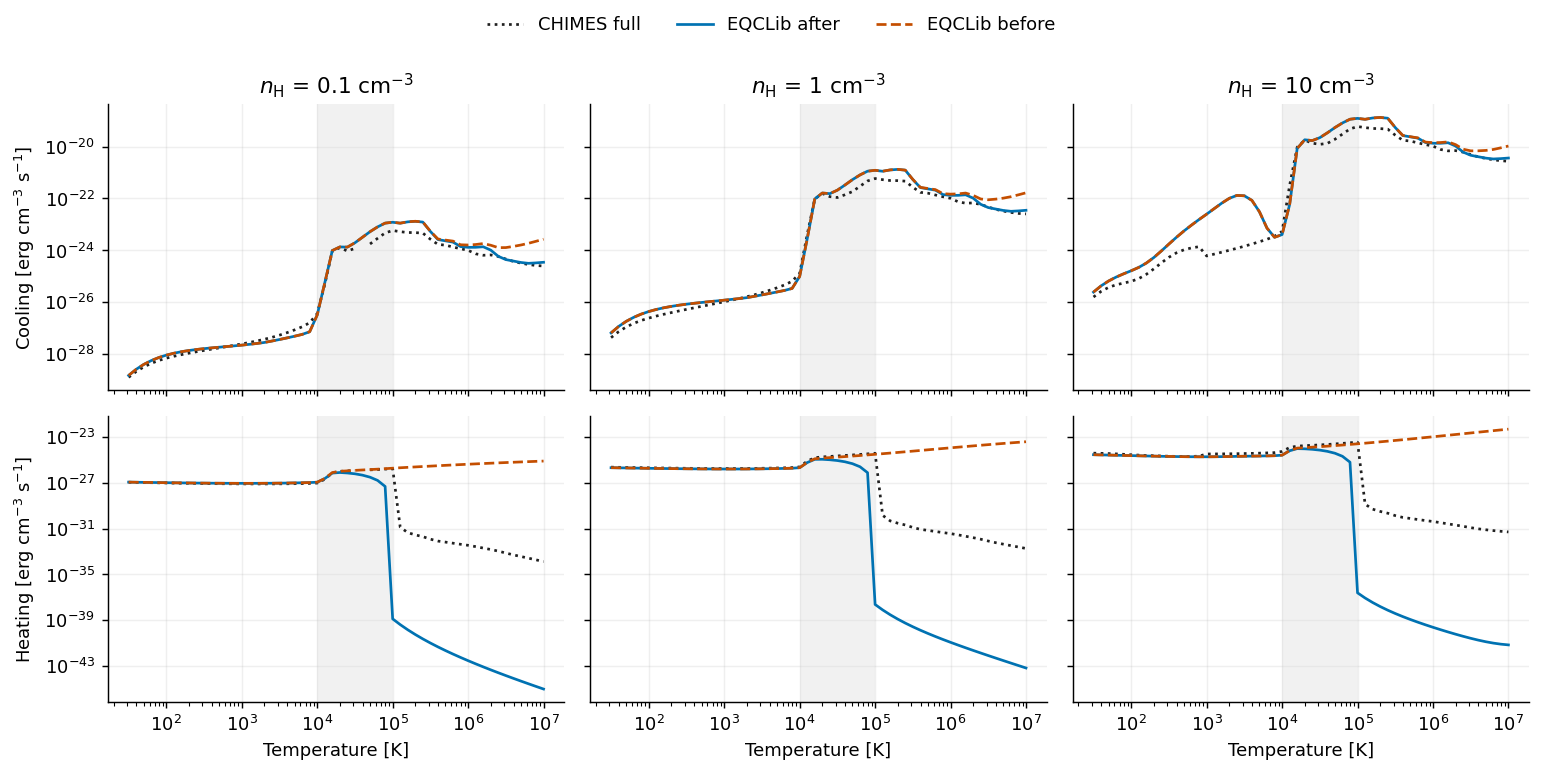

In [3]:
densities = sorted({row["nH"] for row in history["chimes_full"]})
fig, axes = plt.subplots(2, len(densities), figsize=(12, 6), sharex=True, sharey="row", squeeze=False)
for i, density in enumerate(densities):
    axes[0, i].set_title(rf"$n_{{\rm H}}$ = {density:g} cm$^{{-3}}$")
    for j, field in enumerate(("cool", "heat")):
        ax = axes[j, i]
        ax.axvspan(1e4, 1e5, color="#d9d9d9", alpha=0.35, lw=0)
        for model, style in styles.items():
            pts = sorted((t, rates[model][density, t]) for n, t in rates[model] if n == density)
            if pts:
                ax.loglog(
                    [t for t, _ in pts],
                    [r[field] if r["status"] == 0 and r[field] > 0 else np.nan for _, r in pts],
                    **style,
                )
        if j == 1:
            ax.set_xlabel("Temperature [K]")
axes[0, 0].set_ylabel(r"Cooling [erg cm$^{-3}$ s$^{-1}$]")
axes[1, 0].set_ylabel(r"Heating [erg cm$^{-3}$ s$^{-1}$]")
fig.legend(handles=[as_line(**style) for style in styles.values()], loc="upper center", ncol=3)
fig.tight_layout(rect=(0, 0, 1, 0.94))
show(fig)

### CHIMES full に対する冷却率比

3方式の計算が成功し、冷却率が正の共通格子点について集計します。比が 1 のとき冷却率が一致し、1 より大きいと EQCLib の冷却率が大きいことを示します。絶対対数差は $|\log_{10}(\Lambda_{\rm EQCLib}/\Lambda_{\rm CHIMES})|$ です。

In [4]:
common_rates = [
    point for point in sorted(set.intersection(*(set(table) for table in rates.values())))
    if all(table[point]["status"] == 0 and table[point]["cool"] > 0 for table in rates.values())
]
bands = (
    ("10⁴ < T < 10⁵ K", lambda t: 4 < t < 5),
    ("10⁵ ≤ T < 10⁶ K", lambda t: 5 <= t < 6),
    ("10⁶ ≤ T < 10⁶·⁵ K", lambda t: 6 <= t < 6.5),
    ("10⁶·⁵ ≤ T ≤ 10⁷ K", lambda t: 6.5 <= t <= 7),
)
lines = [
    "| 温度域 | 共通点数 | 冷却率比の中央値 変更前 → 変更後 | 絶対対数差の中央値 変更前 → 変更後 |",
    "|---|---:|---:|---:|",
]
for label, includes in bands:
    points = [point for point in common_rates if includes(round(math.log10(point[1]), 8))]
    if not points:
        continue
    ratios = {
        model: [rates[model][point]["cool"] / rates["chimes_full"][point]["cool"] for point in points]
        for model in ("before", "after")
    }
    before, after = (np.median(ratios[model]) for model in ("before", "after"))
    err_before, err_after = (np.median(np.abs(np.log10(ratios[model]))) for model in ("before", "after"))
    lines.append(f"| {label} | {len(points)} | {before:.3g} → {after:.3g} | {err_before:.3f} → {err_after:.3f} dex |")
display(Markdown("\n".join(lines)))

| 温度域 | 共通点数 | 冷却率比の中央値 変更前 → 変更後 | 絶対対数差の中央値 変更前 → 変更後 |
|---|---:|---:|---:|
| 10⁴ < T < 10⁵ K | 214 | 1.79 → 1.79 | 0.335 → 0.335 dex |
| 10⁵ ≤ T < 10⁶ K | 246 | 2.05 → 1.99 | 0.313 → 0.299 dex |
| 10⁶ ≤ T < 10⁶·⁵ K | 125 | 1.76 → 1.5 | 0.245 → 0.176 dex |
| 10⁶·⁵ ≤ T ≤ 10⁷ K | 150 | 2.22 → 1.06 | 0.346 → 0.028 dex |

## 等積冷却履歴

初期温度と水素核密度ごとに温度の時間発展を比較します。対数時間軸には $t>0$ の点を表示します。×印は更新に失敗した履歴の最後の成功点で、失敗した更新の時刻は下の表に示します。

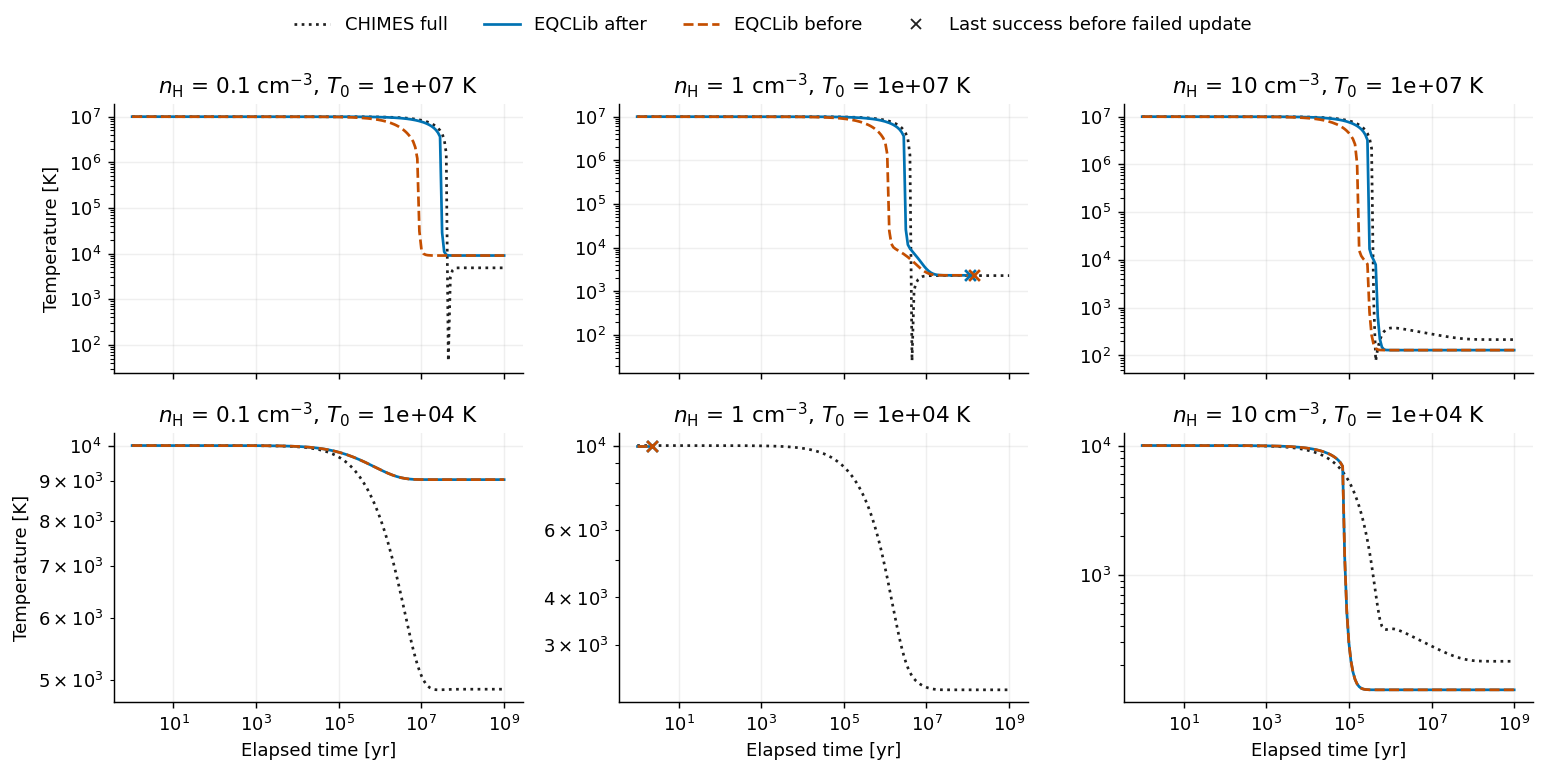

In [5]:
initial_temperatures = sorted({row["T0"] for row in history["chimes_full"]}, reverse=True)
fig, axes = plt.subplots(len(initial_temperatures), len(densities), figsize=(12, 6), sharex=True, squeeze=False)
for j, init in enumerate(initial_temperatures):
    for i, density in enumerate(densities):
        ax = axes[j, i]
        for model, style in styles.items():
            rows = series_at(history[model], density, init)
            good = [row for row in rows if row["t_yr"] > 0 and row["status"] == 0]
            ax.loglog([row["t_yr"] for row in good], [row["T"] for row in good], **style)
            if good and any(row["status"] != 0 for row in rows):
                last = good[-1]
                ax.scatter(last["t_yr"], last["T"], marker="x", color=style["color"], zorder=4)
        ax.set_title(rf"$n_{{\rm H}}$ = {density:g} cm$^{{-3}}$, $T_0$ = {init:.0e} K")
        if j == len(initial_temperatures) - 1:
            ax.set_xlabel("Elapsed time [yr]")
        if i == 0:
            ax.set_ylabel("Temperature [K]")
handles = [as_line(**style) for style in styles.values()]
if any(row["status"] != 0 for rows in history.values() for row in rows):
    handles.append(as_line("Last success before failed update", color=BLACK, marker="x", linestyle="none"))
fig.legend(handles=handles, loc="upper center", ncol=len(handles))
fig.tight_layout(rect=(0, 0, 1, 0.94))
show(fig)

### 冷却時間と更新失敗

$10^6$、$10^5$、$10^4\,{\rm K}$ を初めて下回る時刻を、前後の成功点の対数温度・対数時間の線形補間で求めます。高温から始めた履歴のみを対象にします。

In [6]:
def crossing_time(rows, threshold):
    good = [row for row in rows if row["status"] == 0]
    for left, right in zip(good, good[1:]):
        if left["T"] > threshold >= right["T"]:
            if left["t_yr"] == 0:
                return f"≤ {right['t_yr']:.3g}"
            fraction = math.log(threshold / left["T"]) / math.log(right["T"] / left["T"])
            time = left["t_yr"] * (right["t_yr"] / left["t_yr"]) ** fraction
            return f"{time:.3g}"
    return "未到達"


thresholds = (1e6, 1e5, 1e4)
lines = [
    "| $n_{\\rm H}$ [cm⁻³] | 方式 | $T_0$ [K] | $10^6$ K [yr] | $10^5$ K [yr] | $10^4$ K [yr] |",
    "|---:|---|---:|---:|---:|---:|",
]
for init in (t for t in initial_temperatures if t > thresholds[0]):
    for density in densities:
        for model in ("before", "after", "chimes_full"):
            rows = series_at(history[model], density, init)
            times = " | ".join(crossing_time(rows, threshold) for threshold in thresholds)
            lines.append(f"| {density:g} | {labels_ja[model]} | {init:.0e} | {times} |")
display(Markdown("\n".join(lines)))

failures = [(model, row) for model, rows in history.items() for row in rows if row["status"] != 0]
if failures:
    lines = [
        "**履歴が途中で止まった更新**",
        "",
        "| 方式 | $n_{\\rm H}$ [cm⁻³] | $T_0$ [K] | 試行時刻 [yr] | CSV ステータス |",
        "|---|---:|---:|---:|---:|",
    ]
    for model, row in failures:
        lines.append(
            f"| {labels_ja[model]} | {row['nH']:g} | {row['T0']:.0e} | "
            f"{row['t_yr']:.4g} | {row['status']:g} |"
        )
    display(Markdown("\n".join(lines)))
else:
    display(Markdown("記録された全履歴が最後まで進みました。"))

| $n_{\rm H}$ [cm⁻³] | 方式 | $T_0$ [K] | $10^6$ K [yr] | $10^5$ K [yr] | $10^4$ K [yr] |
|---:|---|---:|---:|---:|---:|
| 0.1 | EQCLib 変更前 | 1e+07 | 7.99e+06 | 8.59e+06 | 1.12e+07 |
| 0.1 | EQCLib 変更後 | 1e+07 | 2.91e+07 | 3.07e+07 | 3.8e+07 |
| 0.1 | CHIMES full | 1e+07 | 4e+07 | 4.1e+07 | 4.21e+07 |
| 1 | EQCLib 変更前 | 1e+07 | 1.13e+06 | 1.21e+06 | 1.63e+06 |
| 1 | EQCLib 変更後 | 1e+07 | 2.9e+06 | 3.06e+06 | 3.88e+06 |
| 1 | CHIMES full | 1e+07 | 3.99e+06 | 4.09e+06 | 4.19e+06 |
| 10 | EQCLib 変更前 | 1e+07 | 1.59e+05 | 1.69e+05 | 2.35e+05 |
| 10 | EQCLib 変更後 | 1e+07 | 2.89e+05 | 3.04e+05 | 3.96e+05 |
| 10 | CHIMES full | 1e+07 | 3.59e+05 | 3.73e+05 | 3.86e+05 |

**履歴が途中で止まった更新**

| 方式 | $n_{\rm H}$ [cm⁻³] | $T_0$ [K] | 試行時刻 [yr] | CSV ステータス |
|---|---:|---:|---:|---:|
| EQCLib 変更後 | 1 | 1e+07 | 1.259e+08 | 1 |
| EQCLib 変更後 | 1 | 1e+04 | 2.512 | 1 |
| EQCLib 変更前 | 1 | 1e+07 | 1.585e+08 | 1 |
| EQCLib 変更前 | 1 | 1e+04 | 2.512 | 1 |

## 化学平衡モードの収束性

以下では **ダスト処方は両版とも修正後**とし、旧 CIE 表を共通にして、EQCLib の化学平衡モードの陰的エネルギー更新だけを比較します。従来停止した 2 条件は $n_{\mathrm{H}}=1\,\mathrm{cm^{-3}}$ で、初期温度は $10^4$ と $10^7\,\mathrm{K}$ です。両版とも、時間刻み、初期の平衡組成、照射・遮蔽条件をそろえています。

通常の化学平衡の許容誤差と、機械精度に近い下限での探索がいずれも `EQC_NO_CONVERGENCE` で終わった場合、修正版は通常の許容誤差から1桁ずつ厳しくした中間値で探索を追加します。受理判定には同じエネルギー残差と熱更新の許容誤差を使います。

$n_{\mathrm{H}}=0.1,1,10\,\mathrm{cm^{-3}}$ と 2 通りの初期温度から始めた 6 本の等積冷却履歴を、計画した終了時刻 $10^9$ 年まで検証します。図の × 印は失敗した更新の直前に受理された状態です。表には、失敗した更新が到達する予定だった時刻を示します。 [再計算手順](README.md)

**全時間を完走した履歴　修正前 4 / 6、修正後 6 / 6**

| 水素核密度 [cm⁻³] | 初期温度 [K] | 修正前の最終成功時刻 [年] | 修正前の失敗時刻 [年] | 修正後の最終成功時刻 [年] | 修正後の失敗時刻 [年] |
|---:|---:|---:|---:|---:|---:|
| 0.1 | 1e+04 | 1e+09 | — | 1e+09 | — |
| 0.1 | 1e+07 | 1e+09 | — | 1e+09 | — |
| 1 | 1e+04 | 2.23872 | 2.51189 | 1e+09 | — |
| 1 | 1e+07 | 1.12202e+08 | 1.25893e+08 | 1e+09 | — |
| 10 | 1e+04 | 1e+09 | — | 1e+09 | — |
| 10 | 1e+07 | 1e+09 | — | 1e+09 | — |

| 水素核密度 [cm⁻³] | 初期温度 [K] | 失敗直前の温度 [K] | 失敗した更新の刻み [年] |
|---:|---:|---:|---:|
| 1 | 1e+04 | 9999.97601 | 0.273165 |
| 1 | 1e+07 | 2323.40367 | 1.36907e+07 |

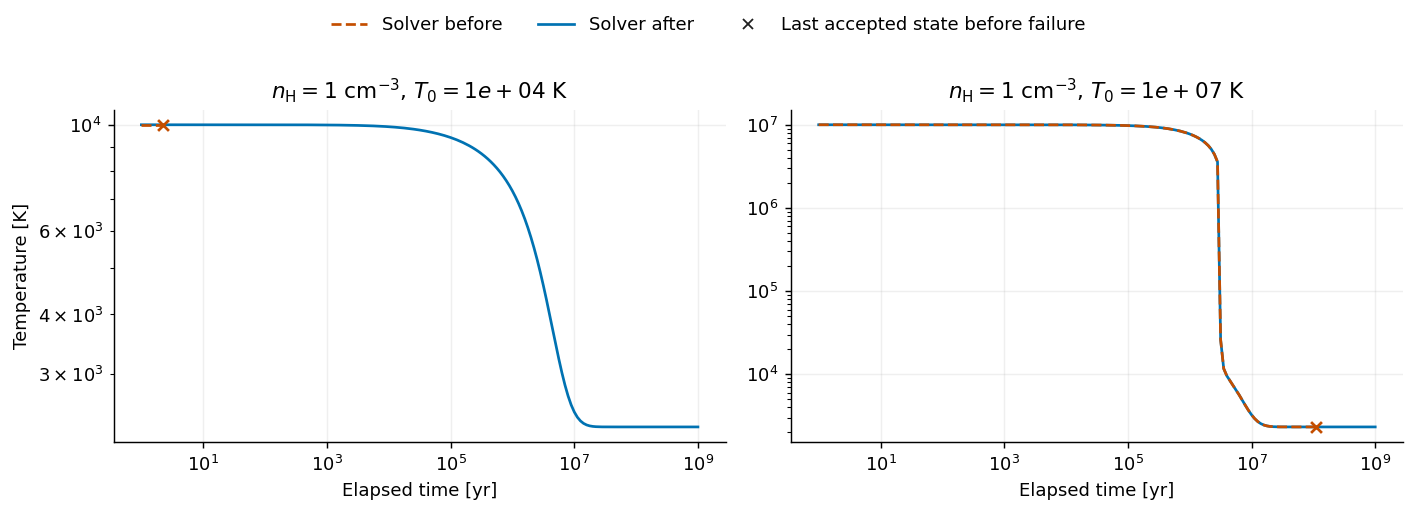

In [7]:
versions = ("before", "after")
version_labels = {"before": "修正前", "after": "修正後"}
solver_styles = {
    "before": dict(label="Solver before", color=ORANGE, linestyle="--", zorder=3),
    "after": dict(label="Solver after", color=BLUE, linestyle="-", zorder=2),
}
solver_histories = {
    version: [row for row in read_table(f"cooling_{version}.csv", convergence_data_dir)
              if row["method"] == "eqclib_eq"]
    for version in versions
}
scenarios = sorted({key_of(row) for rows in solver_histories.values() for row in rows})
paths = {
    (version, density, initial): series_at(solver_histories[version], density, initial)
    for version in versions for density, initial in scenarios
}


def last_success(rows):
    return max((row["t_yr"] for row in rows if row["status"] == 0), default=0.0)


def first_failure(rows):
    return next((row for row in rows if row["status"] != 0), None)


lines = [
    "| 水素核密度 [cm⁻³] | 初期温度 [K] | 修正前の最終成功時刻 [年] | 修正前の失敗時刻 [年] | 修正後の最終成功時刻 [年] | 修正後の失敗時刻 [年] |",
    "|---:|---:|---:|---:|---:|---:|",
]
completed = dict.fromkeys(versions, 0)
for density, initial in scenarios:
    cells = [f"{density:g}", f"{initial:.0e}"]
    for version in versions:
        rows = paths[version, density, initial]
        last = last_success(rows)
        failed = first_failure(rows)
        completed[version] += last == 1e9 and failed is None
        cells.extend([f"{last:.6g}", f"{failed['t_yr']:.6g}" if failed else "—"])
    lines.append("| " + " | ".join(cells) + " |")
display(Markdown(
    f"**全時間を完走した履歴　修正前 {completed['before']} / {len(scenarios)}、"
    f"修正後 {completed['after']} / {len(scenarios)}**\n\n" + "\n".join(lines)
))

original_stops = [case for case in scenarios if first_failure(paths[("before", *case)]) is not None]
if original_stops:
    details = [
        "| 水素核密度 [cm⁻³] | 初期温度 [K] | 失敗直前の温度 [K] | 失敗した更新の刻み [年] |",
        "|---:|---:|---:|---:|",
    ]
    for density, initial in original_stops:
        rows = paths["before", density, initial]
        failed = first_failure(rows)
        previous = next(row for row in reversed(rows)
                        if row["t_yr"] < failed["t_yr"] and row["status"] == 0)
        step_years = failed["t_yr"] - previous["t_yr"]
        details.append(f"| {density:g} | {initial:.0e} | {previous['T']:.9g} | {step_years:.6g} |")
    display(Markdown("\n".join(details)))

    fig, axes = plt.subplots(1, len(original_stops), figsize=(11, 4), squeeze=False)
    for ax, (density, initial) in zip(axes[0], original_stops):
        for version in versions:
            rows = paths[version, density, initial]
            good = [row for row in rows if row["t_yr"] > 0 and row["status"] == 0]
            style = solver_styles[version]
            ax.loglog([row["t_yr"] for row in good], [row["T"] for row in good], **style)
            if good and first_failure(rows) is not None:
                state = good[-1]
                ax.scatter(state["t_yr"], state["T"], marker="x", color=style["color"], zorder=4)
        ax.set_title(rf"$n_{{\rm H}}={density:g}$ cm$^{{-3}}$, $T_0={initial:.0e}$ K")
        ax.set_xlabel("Elapsed time [yr]")
    axes[0, 0].set_ylabel("Temperature [K]")
    handles = [as_line(**style) for style in solver_styles.values()]
    handles.append(as_line("Last accepted state before failure", color=BLACK, marker="x", linestyle="none"))
    fig.legend(handles=handles, loc="upper center", ncol=3)
    fig.tight_layout(rect=(0, 0, 1, 0.90))
    show(fig)

### 従来の計算結果との照合

同じ条件のうち両版で成功した点を対応づけ、温度、数密度分率、出力がある場合は冷却・加熱率を CSV の出力桁で照合します。冷却履歴では同じ時刻に受理された点を使います。成功点を両版で照合し、今回新たに進んだ時刻も区別します。

In [8]:
state_fields = ("T", "xe", "xHII", "fH2", "xHeII", "xHeIII", "xCII", "xCIII", "xCO",
                "xOII", "xOIII", "xSiII", "heat", "cool")


def index_table(stage, version, columns):
    rows = read_table(f"{stage}_{version}.csv", convergence_data_dir)
    return {tuple(row[key] for key in columns): row for row in rows
            if row.get("method", "eqclib_eq") == "eqclib_eq"}


def compare_states(pair_tables):
    before, after = (pair_tables[version] for version in versions)
    old = {key for key, row in before.items() if row["status"] == 0}
    new = {key for key, row in after.items() if row["status"] == 0}
    pairs = [(before[key], after[key]) for key in old & new]
    changed = sum(any(left[key] != right[key] and not (np.isnan(left[key]) and np.isnan(right[key]))
                      for key in state_fields) for left, right in pairs)
    max_temperature = max((abs(right["T"] / left["T"] - 1.0) for left, right in pairs), default=np.nan)
    return len(old), len(new), len(pairs), changed, f"{100 * max_temperature:.3g}%"


comparisons = (
    ("eq", "固定温度の化学平衡", ("nH", "T0")),
    ("timing", "固定刻みの1更新", ("nH", "T0", "dt_yr")),
    ("courant", "クーラン刻みの1更新", ("mass_msun", "nH", "T0", "dt_yr")),
)
lines = [
    "| 計算 | 修正前の成功点 | 修正後の成功点 | 共通成功点 | 出力に差がある共通点 | 温度の最大相対差 |",
    "|---|---:|---:|---:|---:|---:|",
]
for stage, label, columns in comparisons:
    tables = {version: index_table(stage, version, columns) for version in versions}
    lines.append(f"| {label} | " + " | ".join(map(str, compare_states(tables))) + " |")
tables = {version: {history_key(row): row for row in solver_histories[version]} for version in versions}
lines.append("| 等積冷却履歴（初期状態を含む） | " + " | ".join(map(str, compare_states(tables))) + " |")
display(Markdown("\n".join(lines)))

| 計算 | 修正前の成功点 | 修正後の成功点 | 共通成功点 | 出力に差がある共通点 | 温度の最大相対差 |
|---|---:|---:|---:|---:|---:|
| 固定温度の化学平衡 | 1400 | 1400 | 1400 | 0 | 0% |
| 固定刻みの1更新 | 390 | 390 | 390 | 0 | 0% |
| クーラン刻みの1更新 | 260 | 260 | 260 | 0 | 0% |
| 等積冷却履歴（初期状態を含む） | 900 | 1092 | 900 | 0 | 0% |

### 1更新あたりの CPU 時間

単一コアでビルド条件をそろえ、両方で成功したセルの更新だけを集計します。各回で各セルを5回測定し、その中央値を条件群内で合計します。修正前と修正後を1組として7回計測し、どちらを先に実行するかを交互に入れ替えます。下表の更新時間は、各回の合計を共通セル数で割った値の中央値です。CPU 時間の比は同じ測定回の修正後 ÷ 修正前で、1 より小さいほど修正後の CPU 時間が短いことを示します。

In [9]:
measurements = read_table("performance.csv", convergence_data_dir)
groups = sorted({(row["stage"], row["group"]) for row in measurements},
                key=lambda pair: (pair[0] != "timing", pair[1]))
lines = [
    "| 条件群 | 共通セル数 | 測定回数 | 修正前 [µs/更新] | 修正後 [µs/更新] | CPU 時間の比 中央値［最小–最大］ |",
    "|---|---:|---:|---:|---:|---:|",
]
for stage, group in groups:
    by_run = {
        (row["version"], row["repeat"]): row for row in measurements
        if row["stage"] == stage and row["group"] == group
    }
    repeats = sorted({repeat for _, repeat in by_run if all((version, repeat) in by_run for version in versions)})
    counts = {by_run[version, repeat]["comparable_cells"] for version in versions for repeat in repeats}
    assert len(counts) == 1, (stage, group, counts)
    count = counts.pop()
    times = {version: np.array([by_run[version, repeat]["cpu_us"] / count for repeat in repeats])
             for version in versions}
    ratios = times["after"] / times["before"]
    label = f"固定刻み {group:g} 年" if stage == "timing" else f"クーラン刻み {group:g} M☉"
    lines.append(
        f"| {label} | {count:g} | {len(repeats)} | "
        f"{np.median(times['before']):.3g} | {np.median(times['after']):.3g} | "
        f"{np.median(ratios):.3f}［{np.min(ratios):.3f}–{np.max(ratios):.3f}］ |"
    )
display(Markdown("\n".join(lines)))

| 条件群 | 共通セル数 | 測定回数 | 修正前 [µs/更新] | 修正後 [µs/更新] | CPU 時間の比 中央値［最小–最大］ |
|---|---:|---:|---:|---:|---:|
| 固定刻み 10 年 | 130 | 7 | 30.2 | 31.1 | 1.019［0.969–1.235］ |
| 固定刻み 10000 年 | 130 | 7 | 109 | 112 | 1.016［0.962–1.039］ |
| 固定刻み 1e+06 年 | 130 | 7 | 213 | 217 | 1.003［0.969–1.036］ |
| クーラン刻み 100 M☉ | 130 | 7 | 127 | 128 | 1.015［0.950–1.128］ |
| クーラン刻み 10000 M☉ | 130 | 7 | 160 | 160 | 0.993［0.975–1.076］ |

## CIE 冷却表の変更と CHIMES matched

変更前は Sutherland & Dopita (1993) の集約表から H・He の寄与を差し引いた金属冷却を使います。C・O・Si 版は Gnat & Ferland (2012) の CIE 元素別係数を使い、C・O・Si それぞれについて電子数密度と元素数密度を掛けて足し合わせます。H と He の冷却は両版とも EQCLib の個別の項で計算します。ダスト処方と平衡モードの収束修正は両版で共通です。冷却データの出典も変わるため、前後の差には元素組成と係数の両方の影響が含まれます。 [Gnat & Ferland (2012) §3.1](https://arxiv.org/abs/1111.6980)

係数は低密度で光学的に薄いプラズマの衝突電離平衡を仮定します。表は $10^4$–$10^8\,{\rm K}$ の 189 点です。化学平衡モードでは温度・係数の対数を線形補間し、非平衡モードでは Steffen 補間を使います。下限より低い温度では従来の指数抑制を適用し、上限より高い温度では $10^9\,{\rm K}$ まで $T^{1/2}$ で延長します。

CHIMES は `matched` を使い、水素核あたりの元素量を EQCLib の C・O・Si 版とそろえます。He/H は 0.100、C/H は $3.019952\times10^{-4}$、O/H は $4.570882\times10^{-4}$、Si/H は $3.548134\times10^{-6}$ です。CHIMES と EQCLib には反応率や低温の冷却処方にも差があります。両コードを同じ照射・遮蔽条件で比較し、それぞれの化学平衡組成から等積冷却を開始します。時間発展では EQCLib が化学平衡更新、CHIMES が非平衡更新を使います。

リポジトリルートで `bash test/chimes/shielded/run_cie_comparison.sh` を実行し、生成した CSV から下の図と表を作ります。別の出力先を使うときは `cie_data_dir` を変更してください。 [比較条件と再計算手順](README.md)

In [10]:
cie_data_dir = root / "test/out/chimes/shielded/cie_supplement"
cie_versions = ("before", "after")
cie_models = (*cie_versions, "chimes_matched")
cie_styles = {
    "before": dict(label="EQCLib SD93", color=ORANGE, linestyle="--", zorder=4),
    "after": dict(label="EQCLib C/O/Si", color=BLUE, linestyle="-", zorder=3),
    "chimes_matched": dict(label="CHIMES matched", color=BLACK, linestyle=":", zorder=5),
}
cie_labels = {"before": "EQCLib SD93", "after": "EQCLib C・O・Si", "chimes_matched": "CHIMES matched"}
cie_rates = {
    model: {key_of(row): row for row in read_table(f"eq_{model}.csv", cie_data_dir)}
    for model in cie_models
}
cie_histories = {
    model: [row for row in read_table(f"cooling_{model}.csv", cie_data_dir)
            if row["method"] in ("eqclib_eq", "chimes_matched")]
    for model in cie_models
}
cie_scenarios = sorted(set.intersection(*(set(map(key_of, rows)) for rows in cie_histories.values())))
cie_densities = sorted({density for density, _ in cie_scenarios})
cie_initial_temperatures = sorted({initial for _, initial in cie_scenarios}, reverse=True)
cie_paths = {
    (model, *case): series_at(cie_histories[model], *case)
    for model in cie_models for case in cie_scenarios
}

### 固定温度の冷却率

冷却率は体積あたりの全冷却率です。下段は同じ密度・温度での CHIMES matched に対する比です。曲線は計算が成功し冷却率が正の点を結びます。表は全密度の格子で3方式がこの条件を満たした点を集計します。絶対対数差 $|\log_{10}(\Lambda_{\rm EQCLib}/\Lambda_{\rm CHIMES})|$ が小さいほど、冷却率は CHIMES に近づきます。

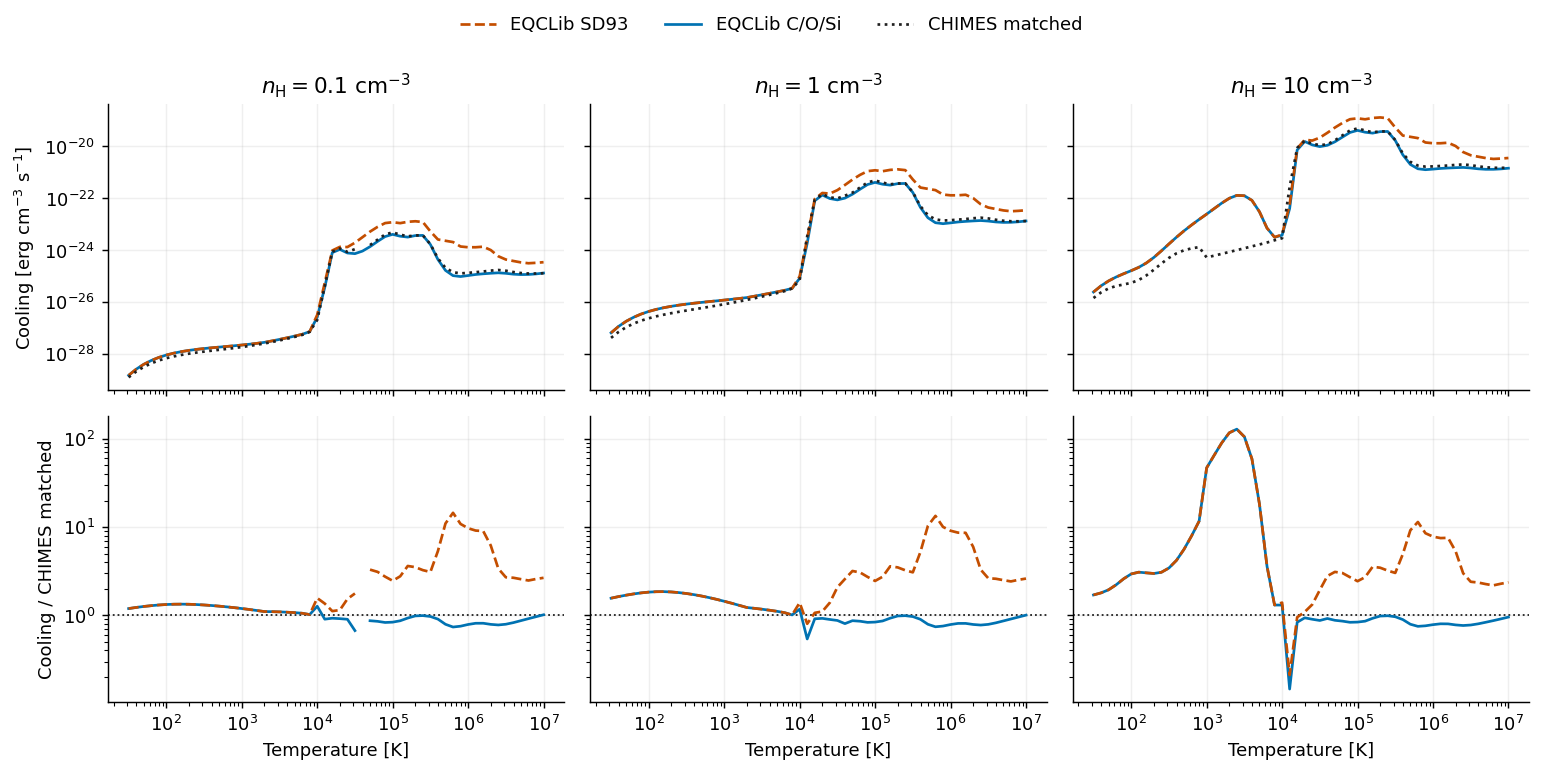

| 温度域 | 共通点数 | EQCLib / CHIMES の中央値 変更前 → 変更後 | 絶対対数差の中央値 [dex] 変更前 → 変更後 |
|---|---:|---:|---:|
| $T \le 10^4$ K | 647 | 1.69 → 1.68 | 0.243 → 0.243 |
| $10^4 < T < 10^5$ K | 213 | 1.92 → 0.879 | 0.333 → 0.056 |
| $10^5 \le T < 10^{5.5}$ K | 121 | 3.22 → 0.928 | 0.508 → 0.032 |
| $10^{5.5} \le T < 10^6$ K | 125 | 8.52 → 0.793 | 0.931 → 0.100 |
| $10^6 \le T < 10^{6.5}$ K | 125 | 7.09 → 0.794 | 0.851 → 0.100 |
| $10^{6.5} \le T \le 10^7$ K | 150 | 2.32 → 0.868 | 0.366 → 0.061 |
| $10^5 \le T \le 10^7$ K（全体） | 521 | 3.26 → 0.837 | 0.513 → 0.078 |

固定温度の平衡計算の成功点数は EQCLib SD93 1400 / 1400、EQCLib C・O・Si 1400 / 1400、CHIMES matched 1381 / 1400 です。

In [11]:
def usable_cooling(row):
    return row["status"] == 0 and math.isfinite(row["cool"]) and row["cool"] > 0


cie_common_rates = sorted(
    point for point in set.intersection(*(set(table) for table in cie_rates.values()))
    if all(usable_cooling(table[point]) for table in cie_rates.values())
)
fig, axes = plt.subplots(2, len(cie_densities), figsize=(12, 6),
                         sharex="col", sharey="row", squeeze=False)
for i, density in enumerate(cie_densities):
    axes[0, i].set_title(rf"$n_{{\rm H}}={density:g}$ cm$^{{-3}}$")
    axes[1, i].axhline(1, color=BLACK, linewidth=1, linestyle=":")
    for model, style in cie_styles.items():
        points = sorted(point for point in cie_rates[model] if point[0] == density)
        rows = [cie_rates[model][point] for point in points]
        values = [row["cool"] if usable_cooling(row) else np.nan for row in rows]
        temperatures = [point[1] for point in points]
        axes[0, i].loglog(temperatures, values, **style)
        if model == "chimes_matched":
            continue
        comparison = [cie_rates["chimes_matched"].get(point) for point in points]
        ratios = [value / row["cool"] if row and usable_cooling(row) else np.nan
                  for value, row in zip(values, comparison)]
        axes[1, i].loglog(temperatures, ratios, **style)
    axes[1, i].set_xlabel("Temperature [K]")
axes[0, 0].set_ylabel(r"Cooling [erg cm$^{-3}$ s$^{-1}$]")
axes[1, 0].set_ylabel("Cooling / CHIMES matched")
fig.legend(handles=[as_line(**style) for style in cie_styles.values()],
           loc="upper center", ncol=3)
fig.tight_layout(rect=(0, 0, 1, 0.94))
show(fig)

lines = [
    "| 温度域 | 共通点数 | EQCLib / CHIMES の中央値 変更前 → 変更後 | 絶対対数差の中央値 [dex] 変更前 → 変更後 |",
    "|---|---:|---:|---:|",
]
cie_band_edges = (
    (r"$T \le 10^4$ K", lambda t: t <= 4),
    (r"$10^4 < T < 10^5$ K", lambda t: 4 < t < 5),
    (r"$10^5 \le T < 10^{5.5}$ K", lambda t: 5 <= t < 5.5),
    (r"$10^{5.5} \le T < 10^6$ K", lambda t: 5.5 <= t < 6),
    (r"$10^6 \le T < 10^{6.5}$ K", lambda t: 6 <= t < 6.5),
    (r"$10^{6.5} \le T \le 10^7$ K", lambda t: 6.5 <= t <= 7),
    (r"$10^5 \le T \le 10^7$ K（全体）", lambda t: 5 <= t <= 7),
)
for band, includes in cie_band_edges:
    points = [point for point in cie_common_rates if includes(round(math.log10(point[1]), 8))]
    if not points:
        continue
    ratios = {version: np.array([cie_rates[version][point]["cool"] / cie_rates["chimes_matched"][point]["cool"]
                                 for point in points])
              for version in cie_versions}
    median_ratios = " → ".join(f"{np.median(ratios[version]):.3g}" for version in cie_versions)
    median_errors = " → ".join(f"{np.median(np.abs(np.log10(ratios[version]))):.3f}" for version in cie_versions)
    lines.append(f"| {band} | {len(points)} | {median_ratios} | {median_errors} |")
counts = "、".join(f"{cie_labels[model]} {sum(row['status'] == 0 for row in cie_rates[model].values())}"
                  f" / {len(cie_rates[model])}" for model in cie_models)
display(Markdown("\n".join(lines) + f"\n\n固定温度の平衡計算の成功点数は {counts} です。"))

### 等積冷却履歴

$T_0=10^7\,{\rm K}$ と $10^4\,{\rm K}$ からの温度履歴を比較します。表には高温からの履歴で $10^6$、$10^5$、$10^4\,{\rm K}$ を初めて下回った時刻を示します。時刻は記録された前後の点を使い、対数時間・対数温度で線形補間します。冷却履歴には、固定温度の冷却率の違いと化学の時間発展の扱いの両方が反映されます。

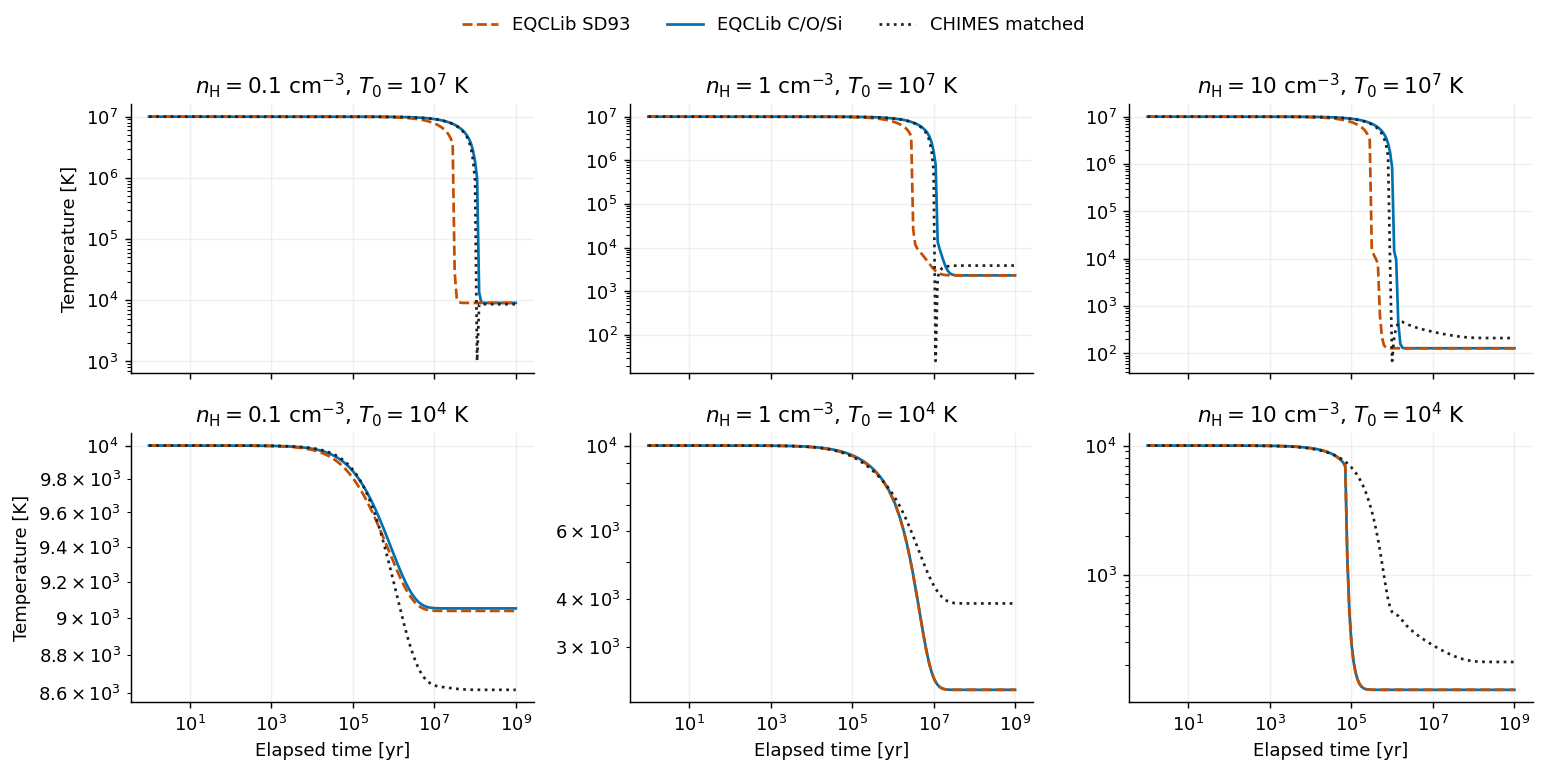

| 水素核密度 [cm⁻³] | 方式 | $10^6$ K [年] | $10^5$ K [年] | $10^4$ K [年] |
|---:|---|---:|---:|---:|
| 0.1 | EQCLib SD93 | 2.91e+07 | 3.07e+07 | 3.8e+07 |
| 0.1 | EQCLib C・O・Si | 1.12e+08 | 1.19e+08 | 1.39e+08 |
| 0.1 | CHIMES matched | 9.87e+07 | 1.04e+08 | 1.08e+08 |
| 1 | EQCLib SD93 | 2.9e+06 | 3.06e+06 | 3.88e+06 |
| 1 | EQCLib C・O・Si | 1.08e+07 | 1.19e+07 | 1.38e+07 |
| 1 | CHIMES matched | 9.43e+06 | 1.02e+07 | 1.05e+07 |
| 10 | EQCLib SD93 | 2.89e+05 | 3.04e+05 | 3.96e+05 |
| 10 | EQCLib C・O・Si | 9.72e+05 | 1.06e+06 | 1.24e+06 |
| 10 | CHIMES matched | 8.01e+05 | 8.43e+05 | 8.86e+05 |

$10^9$ 年まで完走した履歴は EQCLib SD93 6 / 6、EQCLib C・O・Si 6 / 6、CHIMES matched 6 / 6 です。

In [12]:
fig, axes = plt.subplots(len(cie_initial_temperatures), len(cie_densities), figsize=(12, 6),
                         sharex=True, squeeze=False)
for j, initial in enumerate(cie_initial_temperatures):
    for i, density in enumerate(cie_densities):
        ax = axes[j, i]
        exponent = round(math.log10(initial))
        ax.set_title(rf"$n_{{\rm H}}={density:g}$ cm$^{{-3}}$, $T_0=10^{{{exponent}}}$ K")
        for model, style in cie_styles.items():
            rows = cie_paths[model, density, initial]
            good = [row for row in rows if row["t_yr"] > 0 and row["status"] == 0]
            ax.loglog([row["t_yr"] for row in good], [row["T"] for row in good], **style)
            if good and first_failure(rows) is not None:
                state = good[-1]
                ax.scatter(state["t_yr"], state["T"], marker="x", color=style["color"], zorder=6)
        if i == 0:
            ax.set_ylabel("Temperature [K]")
        if j == len(cie_initial_temperatures) - 1:
            ax.set_xlabel("Elapsed time [yr]")
handles = [as_line(**style) for style in cie_styles.values()]
if any(first_failure(rows) is not None for rows in cie_paths.values()):
    handles.append(as_line("Last success before failed update", color=BLACK, marker="x", linestyle="none"))
fig.legend(handles=handles, loc="upper center", ncol=len(handles))
fig.tight_layout(rect=(0, 0, 1, 0.94))
show(fig)

lines = [
    "| 水素核密度 [cm⁻³] | 方式 | $10^6$ K [年] | $10^5$ K [年] | $10^4$ K [年] |",
    "|---:|---|---:|---:|---:|",
]
for density, initial in cie_scenarios:
    if initial <= 1e6:
        continue
    for model in cie_models:
        rows = cie_paths[model, density, initial]
        times = " | ".join(crossing_time(rows, threshold) for threshold in (1e6, 1e5, 1e4))
        lines.append(f"| {density:g} | {cie_labels[model]} | {times} |")
completed = {
    model: sum(last_success(cie_paths[(model, *case)]) == 1e9
               and first_failure(cie_paths[(model, *case)]) is None for case in cie_scenarios)
    for model in cie_models
}
counts = "、".join(f"{cie_labels[model]} {completed[model]} / {len(cie_scenarios)}" for model in cie_models)
display(Markdown("\n".join(lines) + f"\n\n$10^9$ 年まで完走した履歴は {counts} です。"))

### 低温での変更前後の差

固定温度の $T\le10^4\,{\rm K}$ の格子点と、$T_0\le10^4\,{\rm K}$ の履歴で両版の温度がこの範囲にある共通の記録を照合します。相対差は $|q_{\rm after}-q_{\rm before}|/\max(|q_{\rm after}|,|q_{\rm before}|)$ で、両版ともゼロのときは 0 とします。CSV の出力桁で比較します。

In [13]:
cie_low_rates = [
    tuple(cie_rates[version][point] for version in cie_versions)
    for point in sorted(cie_rates["before"].keys() & cie_rates["after"].keys())
    if point[1] <= 1e4 and all(cie_rates[version][point]["status"] == 0 for version in cie_versions)
]
cie_history_tables = {
    version: {(row["nH"], row["T0"], row["t_yr"]): row
              for row in cie_histories[version]
              if row["T0"] <= 1e4 and row["T"] <= 1e4 and row["status"] == 0}
    for version in cie_versions
}
cie_low_history = [
    tuple(cie_history_tables[version][point] for version in cie_versions)
    for point in sorted(cie_history_tables["before"].keys() & cie_history_tables["after"].keys())
]


def max_symmetric_difference(before, after):
    scale = np.maximum(np.abs(before), np.abs(after))
    return np.max(np.divide(np.abs(after - before), scale, where=scale > 0,
                            out=np.zeros_like(scale)))


lines = [
    "| 記録 | 量 | 共通成功点数 | 値に差がある点数 | 最大相対差 |",
    "|---|---|---:|---:|---:|",
]
cie_low_samples = (
    ("固定温度 $T<10^4$ K", [pair for pair in cie_low_rates if pair[0]["T0"] < 1e4]),
    ("固定温度 $T=10^4$ K", [pair for pair in cie_low_rates if pair[0]["T0"] == 1e4]),
    ("等積冷却履歴（初期状態を含む）", cie_low_history),
)
for sample, pairs in cie_low_samples:
    if not pairs:
        continue
    for field, label in (("T", "温度"), ("cool", "冷却率"), ("heat", "加熱率"),
                         ("xe", "電子分率"), ("fH2", "水素分子分率")):
        before, after = np.array([(left[field], right[field]) for left, right in pairs]).T
        valid = np.isfinite(before) & np.isfinite(after)
        if not np.any(valid):
            continue
        before, after = before[valid], after[valid]
        maximum = max_symmetric_difference(before, after)
        lines.append(f"| {sample} | {label} | {len(before)} | {np.count_nonzero(before != after)} | {100 * maximum:.3g}% |")
display(Markdown("\n".join(lines)))

| 記録 | 量 | 共通成功点数 | 値に差がある点数 | 最大相対差 |
|---|---|---:|---:|---:|
| 固定温度 $T<10^4$ K | 温度 | 625 | 0 | 0% |
| 固定温度 $T<10^4$ K | 冷却率 | 625 | 33 | 0.00355% |
| 固定温度 $T<10^4$ K | 加熱率 | 625 | 0 | 0% |
| 固定温度 $T<10^4$ K | 電子分率 | 625 | 0 | 0% |
| 固定温度 $T<10^4$ K | 水素分子分率 | 625 | 0 | 0% |
| 固定温度 $T=10^4$ K | 温度 | 25 | 0 | 0% |
| 固定温度 $T=10^4$ K | 冷却率 | 25 | 25 | 19.4% |
| 固定温度 $T=10^4$ K | 加熱率 | 25 | 0 | 0% |
| 固定温度 $T=10^4$ K | 電子分率 | 25 | 0 | 0% |
| 固定温度 $T=10^4$ K | 水素分子分率 | 25 | 0 | 0% |
| 等積冷却履歴（初期状態を含む） | 温度 | 546 | 479 | 0.594% |
| 等積冷却履歴（初期状態を含む） | 冷却率 | 546 | 481 | 19.2% |
| 等積冷却履歴（初期状態を含む） | 加熱率 | 546 | 469 | 0.299% |
| 等積冷却履歴（初期状態を含む） | 電子分率 | 546 | 511 | 0.438% |
| 等積冷却履歴（初期状態を含む） | 水素分子分率 | 546 | 475 | 3.1% |

### 計算速度への影響

化学平衡モードの更新を修正前後で同じビルド条件・同じコアで測ります。固定刻みは 10、$10^4$、$10^6$ 年です。クーラン刻みは粒子質量 $10^2$、$10^4\,M_\odot$ を使います。各反復の CPU 時間は、両版で成功した各条件の更新時間の中央値を足し、共通条件数で割った値です。同じ反復の変更後と変更前の比を取り、中央値と実測範囲を示します。冷却率の変更による陰的更新の反復回数の変化もこの計測に含まれます。

In [14]:
cie_measurements = read_table("performance.csv", cie_data_dir)
cie_groups = sorted({(row["stage"], row["group"]) for row in cie_measurements},
                    key=lambda pair: (pair[0] != "timing", pair[1]))
lines = [
    "| 条件群 | 共通セル数 | 反復数 | 変更前 [µs/更新] | 変更後 [µs/更新] | 変更後 / 変更前 中央値［最小–最大］ |",
    "|---|---:|---:|---:|---:|---:|",
]
for stage, group in cie_groups:
    by_run = {
        (row["version"], row["repeat"]): row for row in cie_measurements
        if row["stage"] == stage and row["group"] == group and row["version"] in cie_versions
    }
    repeats = sorted({repeat for _, repeat in by_run})
    assert set(by_run) == {(version, repeat) for version in cie_versions for repeat in repeats}
    counts = [by_run["before", repeat]["comparable_cells"] for repeat in repeats]
    assert counts == [by_run["after", repeat]["comparable_cells"] for repeat in repeats]
    times = {
        version: np.array([by_run[version, repeat]["cpu_us"] / count
                           for repeat, count in zip(repeats, counts)])
        for version in cie_versions
    }
    paired = times["after"] / times["before"]
    count_label = f"{min(counts):g}" if min(counts) == max(counts) else f"{min(counts):g}–{max(counts):g}"
    label = f"固定刻み {group:,.0f} 年" if stage == "timing" else f"クーラン刻み {group:,.0f} M☉"
    lines.append(f"| {label} | {count_label} | {len(repeats)} | "
                 f"{np.median(times['before']):.3g} | {np.median(times['after']):.3g} | "
                 f"{np.median(paired):.3f}［{min(paired):.3f}–{max(paired):.3f}］ |")
display(Markdown("\n".join(lines)))

| 条件群 | 共通セル数 | 反復数 | 変更前 [µs/更新] | 変更後 [µs/更新] | 変更後 / 変更前 中央値［最小–最大］ |
|---|---:|---:|---:|---:|---:|
| 固定刻み 10 年 | 130 | 7 | 31.2 | 29.5 | 0.931［0.873–1.131］ |
| 固定刻み 10,000 年 | 130 | 7 | 116 | 117 | 1.014［0.979–1.039］ |
| 固定刻み 1,000,000 年 | 130 | 7 | 226 | 226 | 1.015［0.991–1.065］ |
| クーラン刻み 100 M☉ | 130 | 7 | 130 | 133 | 1.012［1.001–1.075］ |
| クーラン刻み 10,000 M☉ | 130 | 7 | 163 | 169 | 1.038［0.974–1.067］ |

#### CHIMES matched との速度比較

各方式の 1 回分の全条件の計測を使い、3方式が同じ刻みで成功した条件を比較します。更新時間は各条件の反復測定の中央値です。比が 1 より大きいと EQCLib の更新が速いことを示します。各コードが自身の化学平衡組成から更新を始めます。速度比はこの格子、このビルド、各コードが使う化学更新方式での値です。

In [15]:
lines = [
    "| 条件群 | 共通セル数 | CPU 時間の総和の比 CHIMES / EQCLib 変更前 → 変更後 | 条件別の比の中央値 変更前 → 変更後 |",
    "|---|---:|---:|---:|",
]
for stage, group_field in (("timing", "dt_yr"), ("courant", "mass_msun")):
    tables = {
        model: {(row[group_field], row["nH"], row["T0"]): row
                for row in read_table(f"{stage}_{model}.csv", cie_data_dir)
                if row["method"] in ("eqclib_eq", "chimes_matched") and row["status"] == 0}
        for model in cie_models
    }
    common = sorted(set.intersection(*(set(table) for table in tables.values())))
    for group in sorted({key[0] for key in common}):
        keys_in_group = [key for key in common if key[0] == group]
        assert all(len({table[key]["dt_yr"] for table in tables.values()}) == 1 for key in keys_in_group)
        times = {model: np.array([tables[model][key]["cpu_us_median"] for key in keys_in_group])
                 for model in cie_models}
        chimes = times["chimes_matched"]
        sums = " → ".join(f"{chimes.sum() / times[version].sum():.3g}" for version in cie_versions)
        medians = " → ".join(f"{np.median(chimes / times[version]):.3g}" for version in cie_versions)
        label = f"固定刻み {group:,.0f} 年" if stage == "timing" else f"クーラン刻み {group:,.0f} M☉"
        lines.append(f"| {label} | {len(keys_in_group)} | {sums} | {medians} |")
display(Markdown("\n".join(lines)))

| 条件群 | 共通セル数 | CPU 時間の総和の比 CHIMES / EQCLib 変更前 → 変更後 | 条件別の比の中央値 変更前 → 変更後 |
|---|---:|---:|---:|
| 固定刻み 10 年 | 129 | 9.85 → 10.3 | 0.573 → 0.618 |
| 固定刻み 10,000 年 | 129 | 23.1 → 22.4 | 19 → 19.2 |
| 固定刻み 1,000,000 年 | 129 | 25.6 → 24.2 | 24 → 23.7 |
| クーラン刻み 100 M☉ | 129 | 25.1 → 24.9 | 20.8 → 21.6 |
| クーラン刻み 10,000 M☉ | 129 | 28.1 → 27.2 | 23.5 → 23.7 |

## 未追跡元素を補完した高温 CIE 冷却

C・O・Si の数密度はセルの値を使います。N・Ne・Mg・S・Ca・Fe は太陽光球の存在量で重み付けした Gnat & Ferland の冷却係数を1枚の表にまとめ、$n_e n_{\rm H} Z/0.0134$ を掛けます。補完項は $T\le10^4$ K でゼロ、$T\ge10^5$ K で全量とし、その間を対数温度で滑らかにつなぎます。未追跡元素のダストによる減少は仮定しません。 [Asplund et al. (2009)](https://doi.org/10.1146/annurev.astro.46.060407.145222)

補完版の入力は $Z=0.0134$ です。SD93 版と C・O・Si 版は以前の比較と同じ $Z=0.019$ を使います。正の $Z$ の値は C・O・Si 版の冷却率には影響しません。CHIMES full は同じ H・He・C・O・Si に Wiersma et al. (2009) の6元素を加えるので、EQCLib の補完版とは追加元素の存在比に差があります。EQCLib の3版でダスト処方と収束修正をそろえ、全方式に同じ照射・遮蔽条件を与えます。 [比較条件と再計算手順](README.md)

### 固定温度での冷却率

図の水平線は CHIMES full と同じ全冷却率を表します。表は全密度で4方式が固定温度の化学平衡に達し、冷却率が正の共通格子点を集計します。

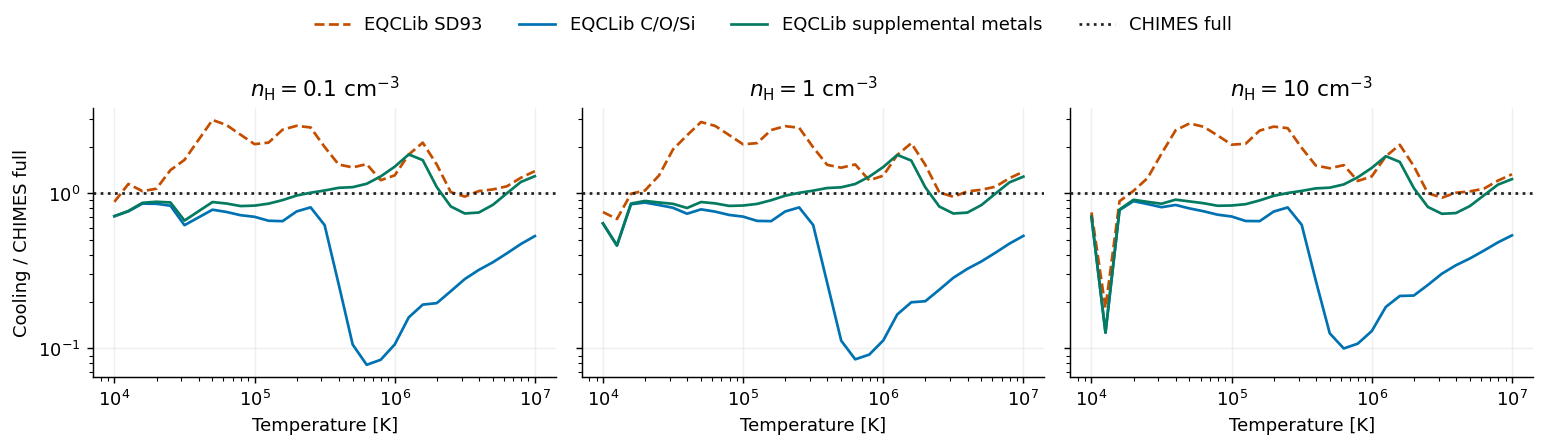

| 温度域 | 共通点数 | SD93 中央値 | C・O・Si 中央値 | 6元素補完 中央値［最小–最大］ |
|---|---:|---:|---:|---:|
| $T \le 10^4$ K | 647 | 1.56 | 1.56 | 1.56［0.0674–577］ |
| $10^4 < T < 10^5$ K | 214 | 1.79 | 0.8 | 0.865［0.0104–0.948］ |
| $10^5 \le T < 10^{5.5}$ K | 121 | 2.55 | 0.709 | 0.902［0.829–1.01］ |
| $10^{5.5} \le T < 10^6$ K | 125 | 1.51 | 0.125 | 1.09［1.04–1.29］ |
| $10^6 \le T < 10^{6.5}$ K | 125 | 1.5 | 0.2 | 1.46［0.817–1.78］ |
| $10^{6.5} \le T \le 10^7$ K | 150 | 1.06 | 0.408 | 0.901［0.739–1.29］ |
| $10^5 \le T \le 10^7$ K（全体） | 521 | 1.49 | 0.333 | 1.04［0.739–1.78］ |

In [16]:
supplement_versions = (*cie_versions, "supplemented")
supplement_models = (*supplement_versions, "chimes_full")
supplement_labels = {**cie_labels, "supplemented": "EQCLib 6元素補完", "chimes_full": "CHIMES full"}
supplement_styles = {
    "before": cie_styles["before"], "after": cie_styles["after"],
    "supplemented": dict(label="EQCLib supplemental metals", color="#047A61", linestyle="-", zorder=5),
    "chimes_full": dict(label="CHIMES full", color=BLACK, linestyle=":", zorder=5),
}
supplement_rates = {
    **{model: cie_rates[model] for model in cie_versions},
    **{model: {key_of(row): row for row in read_table(f"eq_{model}.csv", cie_data_dir)}
       for model in ("supplemented", "chimes_full")},
}
common_rates = sorted(
    point for point in set.intersection(*(set(table) for table in supplement_rates.values()))
    if all(usable_cooling(table[point]) for table in supplement_rates.values())
)
fig, axes = plt.subplots(1, len(cie_densities), figsize=(12, 3.5), sharey=True, squeeze=False)
for ax, density in zip(axes[0], cie_densities):
    ax.set_title(rf"$n_{{\rm H}}={density:g}$ cm$^{{-3}}$")
    ax.axhline(1, **{key: value for key, value in supplement_styles["chimes_full"].items() if key != "label"})
    for version in supplement_versions:
        temperatures = [temperature for nH, temperature in common_rates if nH == density and temperature >= 1e4]
        ratios = [supplement_rates[version][density, t]["cool"] / supplement_rates["chimes_full"][density, t]["cool"]
                  for t in temperatures]
        ax.loglog(temperatures, ratios, **supplement_styles[version])
    ax.set_xlabel("Temperature [K]")
axes[0, 0].set_ylabel("Cooling / CHIMES full")
fig.legend(handles=[as_line(**style) for style in supplement_styles.values()], loc="upper center", ncol=4)
fig.tight_layout(rect=(0, 0, 1, 0.89))
show(fig)

rate_lines = [
    "| 温度域 | 共通点数 | SD93 中央値 | C・O・Si 中央値 | 6元素補完 中央値［最小–最大］ |",
    "|---|---:|---:|---:|---:|",
]
for band, includes in cie_band_edges:
    points = [point for point in common_rates if includes(round(math.log10(point[1]), 8))]
    ratios = {
        version: np.array([supplement_rates[version][point]["cool"] / supplement_rates["chimes_full"][point]["cool"]
                           for point in points])
        for version in supplement_versions
    }
    if not points:
        continue
    adjusted = ratios["supplemented"]
    rate_lines.append(
        f"| {band} | {len(points)} | {np.median(ratios['before']):.3g} | {np.median(ratios['after']):.3g} | "
        f"{np.median(adjusted):.3g}［{adjusted.min():.3g}–{adjusted.max():.3g}］ |"
    )
display(Markdown("\n".join(rate_lines)))

### 等積冷却履歴と低温での照合

時間発展では EQCLib の化学平衡モードと CHIMES full の非平衡更新を使います。図は $10^7$ K から始めた3条件です。表では前後の成功点から冷却時間を対数補間します。低温では C・O・Si 版と補完版の出力を比較します。

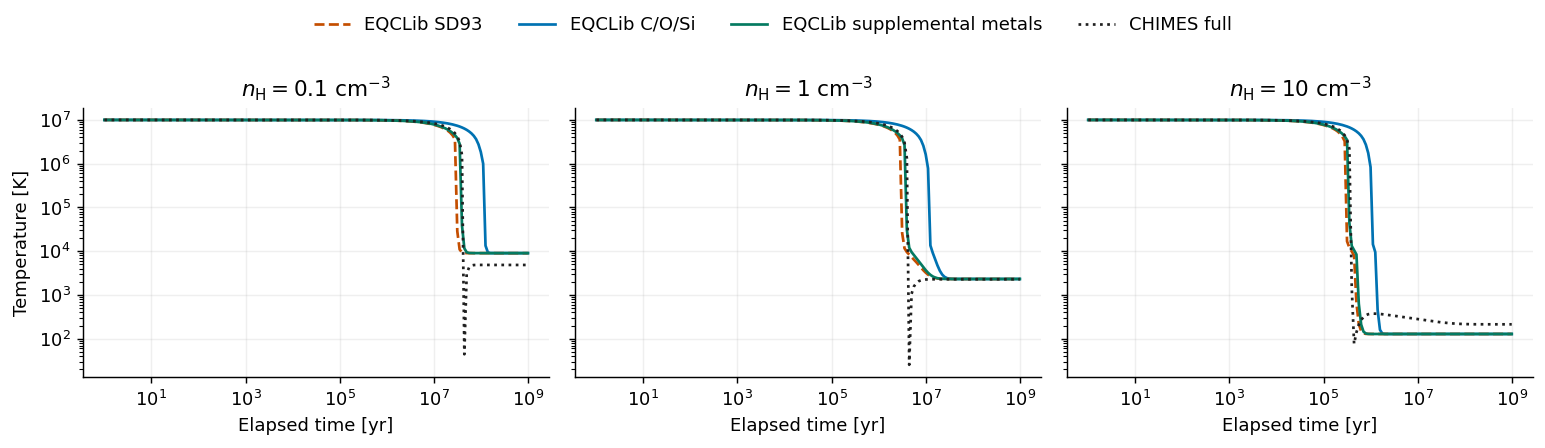

| 水素核密度 [cm⁻³] | 方式 | $10^6$ K 到達 [年] | $2\times10^4$ K 到達 [年] |
|---:|---|---:|---:|
| 0.1 | EQCLib SD93 | 2.91e+07 | 3.3e+07 |
| 0.1 | EQCLib C・O・Si | 1.12e+08 | 1.25e+08 |
| 0.1 | EQCLib 6元素補完 | 3.65e+07 | 4.24e+07 |
| 0.1 | CHIMES full | 4e+07 | 4.18e+07 |
| 1 | EQCLib SD93 | 2.9e+06 | 3.28e+06 |
| 1 | EQCLib C・O・Si | 1.08e+07 | 1.25e+07 |
| 1 | EQCLib 6元素補完 | 3.64e+06 | 4.2e+06 |
| 1 | CHIMES full | 3.99e+06 | 4.16e+06 |
| 10 | EQCLib SD93 | 2.89e+05 | 3.15e+05 |
| 10 | EQCLib C・O・Si | 9.72e+05 | 1.11e+06 |
| 10 | EQCLib 6元素補完 | 3.27e+05 | 3.83e+05 |
| 10 | CHIMES full | 3.59e+05 | 3.82e+05 |

10億年まで完走した履歴は EQCLib SD93 6/6、EQCLib C・O・Si 6/6、EQCLib 6元素補完 6/6、CHIMES full 6/6 です。

| C・O・Si 版と補完版の照合 | 共通点数 | 冷却率の最大相対差 | 加熱率の最大相対差 | 温度の最大相対差 |
|---|---:|---:|---:|---:|
| 固定温度（$T\le10^4$ K） | 650 | 0% | 0% | 0% |
| 等積履歴（$T_0\le10^4$ K） | 546 | 0% | 0% | 0% |

In [17]:
supplement_histories = {
    **{model: cie_histories[model] for model in cie_versions},
    **{model: [row for row in read_table(f"cooling_{model}.csv", cie_data_dir)
               if row["method"] in ("eqclib_eq", "chimes_full")]
       for model in ("supplemented", "chimes_full")},
}
supplement_paths = {
    (model, *case): series_at(supplement_histories[model], *case)
    for model in supplement_models for case in cie_scenarios
}

hot_initial = max(cie_initial_temperatures)
fig, axes = plt.subplots(1, len(cie_densities), figsize=(12, 3.5), sharey=True, squeeze=False)
for ax, density in zip(axes[0], cie_densities):
    ax.set_title(rf"$n_{{\rm H}}={density:g}$ cm$^{{-3}}$")
    for model, style in supplement_styles.items():
        path = supplement_paths[model, density, hot_initial]
        good = [row for row in path if row["t_yr"] > 0 and row["status"] == 0]
        ax.loglog([row["t_yr"] for row in good], [row["T"] for row in good], **style)
    ax.set_xlabel("Elapsed time [yr]")
axes[0, 0].set_ylabel("Temperature [K]")
fig.legend(handles=[as_line(**style) for style in supplement_styles.values()], loc="upper center", ncol=4)
fig.tight_layout(rect=(0, 0, 1, 0.89))
show(fig)

history_lines = [
    r"| 水素核密度 [cm⁻³] | 方式 | $10^6$ K 到達 [年] | $2\times10^4$ K 到達 [年] |",
    "|---:|---|---:|---:|",
]
for density in cie_densities:
    for model in supplement_models:
        path = supplement_paths[model, density, hot_initial]
        times = " | ".join(crossing_time(path, threshold) for threshold in (1e6, 2e4))
        history_lines.append(f"| {density:g} | {supplement_labels[model]} | {times} |")
completed = []
for model in supplement_models:
    paths = [supplement_paths[model, *case] for case in cie_scenarios]
    count = sum(last_success(path) == 1e9 and first_failure(path) is None for path in paths)
    completed.append(f"{supplement_labels[model]} {count}/{len(paths)}")
completed = "、".join(completed)
display(Markdown("\n".join(history_lines) + f"\n\n10億年まで完走した履歴は {completed} です。"))

fixed_low = [
    (supplement_rates["after"][point], supplement_rates["supplemented"][point])
    for point in sorted(supplement_rates["after"].keys() & supplement_rates["supplemented"].keys())
    if point[1] <= 1e4 and all(supplement_rates[version][point]["status"] == 0
                               for version in ("after", "supplemented"))
]
cold_tables = {
    model: {(row["nH"], row["T0"], row["t_yr"]): row for row in supplement_histories[model]
            if row["status"] == 0 and row["T0"] <= 1e4}
    for model in ("after", "supplemented")
}
cold_rows = [
    (cold_tables["after"][point], cold_tables["supplemented"][point])
    for point in sorted(cold_tables["after"].keys() & cold_tables["supplemented"].keys())
]
low_lines = [
    "| C・O・Si 版と補完版の照合 | 共通点数 | 冷却率の最大相対差 | 加熱率の最大相対差 | 温度の最大相対差 |",
    "|---|---:|---:|---:|---:|",
]
for label, pairs in ((r"固定温度（$T\le10^4$ K）", fixed_low), (r"等積履歴（$T_0\le10^4$ K）", cold_rows)):
    changes = []
    for field in ("cool", "heat", "T"):
        old, new = np.asarray([(left[field], right[field]) for left, right in pairs]).T
        valid = np.isfinite(old) & np.isfinite(new)
        difference = max_symmetric_difference(old[valid], new[valid])
        changes.append(f"{100 * difference:.3g}%")
    low_lines.append(f"| {label} | {len(pairs)} | " + " | ".join(changes) + " |")
display(Markdown("\n".join(low_lines)))

### 補完に伴う CPU 時間の変化

EQCLib の3版は同じコアで順番を入れ替えながら7回ずつ測定します。各計測回で共通成功セルの CPU 時間を合計し、補完版と C・O・Si 版の比を求めます。CHIMES full との比は同じコアでの各方式1回分について、同じ刻みで成功した条件の総和と条件別の中央値を示します。

In [18]:
performance_lines = [
    "| 条件群 | 共通セル数 | C・O・Si版 [µs/更新] | 補完版 [µs/更新] | 補完版 / C・O・Si版 中央値［最小–最大］ |",
    "|---|---:|---:|---:|---:|",
]
chimes_lines = [
    "| 条件群 | 共通セル数 | CHIMES full / 補完版 総 CPU 時間の比 | 条件別の比の中央値 |",
    "|---|---:|---:|---:|",
]
for stage, group_field in (("timing", "dt_yr"), ("courant", "mass_msun")):
    timings = {
        model: {(row[group_field], row["nH"], row["T0"]): row
                for row in read_table(f"{stage}_{model}.csv", cie_data_dir)
                if row["method"] in ("eqclib_eq", "chimes_full") and row["status"] == 0}
        for model in ("supplemented", "chimes_full")
    }
    common = sorted(set.intersection(*(set(table) for table in timings.values())))
    groups = [group for label, group in cie_groups if label == stage]
    for group in groups:
        label = f"固定刻み {group:,.0f} 年" if stage == "timing" else f"クーラン刻み {group:,.0f} M☉"
        runs = {
            (row["version"], row["repeat"]): row for row in cie_measurements
            if row["stage"] == stage and row["group"] == group
        }
        repeats = sorted({repeat for _, repeat in runs})
        counts = [runs["after", repeat]["comparable_cells"] for repeat in repeats]
        assert counts == [runs["supplemented", repeat]["comparable_cells"] for repeat in repeats]
        baseline, supplement = [
            np.array([runs[version, repeat]["cpu_us"] / count for repeat, count in zip(repeats, counts)])
            for version in ("after", "supplemented")
        ]
        ratios = supplement / baseline
        count_label = f"{min(counts):g}" if min(counts) == max(counts) else f"{min(counts):g}–{max(counts):g}"
        performance_lines.append(
            f"| {label} | {count_label} | {np.median(baseline):.3g} | {np.median(supplement):.3g} | "
            f"{np.median(ratios):.3f}［{ratios.min():.3f}–{ratios.max():.3f}］ |"
        )
        group_cells = [point for point in common if point[0] == group]
        assert all(timings["supplemented"][point]["dt_yr"] == timings["chimes_full"][point]["dt_yr"]
                   for point in group_cells)
        measured_supplement, chimes = [
            np.array([timings[model][point]["cpu_us_median"] for point in group_cells])
            for model in ("supplemented", "chimes_full")
        ]
        chimes_lines.append(
            f"| {label} | {len(group_cells)} | {chimes.sum() / measured_supplement.sum():.3g} | "
            f"{np.median(chimes / measured_supplement):.3g} |"
        )
display(Markdown("\n".join(performance_lines)))
display(Markdown("\n".join(chimes_lines)))

| 条件群 | 共通セル数 | C・O・Si版 [µs/更新] | 補完版 [µs/更新] | 補完版 / C・O・Si版 中央値［最小–最大］ |
|---|---:|---:|---:|---:|
| 固定刻み 10 年 | 130 | 29.5 | 29.9 | 1.045［0.852–1.069］ |
| 固定刻み 10,000 年 | 130 | 117 | 129 | 1.113［1.072–1.156］ |
| 固定刻み 1,000,000 年 | 130 | 226 | 243 | 1.074［1.022–1.086］ |
| クーラン刻み 100 M☉ | 130 | 133 | 146 | 1.092［1.041–1.173］ |
| クーラン刻み 10,000 M☉ | 130 | 169 | 184 | 1.067［1.055–1.144］ |

| 条件群 | 共通セル数 | CHIMES full / 補完版 総 CPU 時間の比 | 条件別の比の中央値 |
|---|---:|---:|---:|
| 固定刻み 10 年 | 129 | 74.3 | 1.32 |
| 固定刻み 10,000 年 | 129 | 137 | 105 |
| 固定刻み 1,000,000 年 | 129 | 145 | 142 |
| クーラン刻み 100 M☉ | 129 | 154 | 143 |
| クーラン刻み 10,000 M☉ | 129 | 154 | 144 |